# Day 2: Supervised learning on housing affordability

**Group 8** · IAAC MaAI 2026–27 · AI Methods · Day 2

Builds on the Day 1 output `data/housing_affordability_model_ready.csv` (1,210 rows × 29 columns, one row = one country in one year, 1977–2024).

**Task:** predict **next year's affordability** (`affordability_next`) for a country, from what is known this year.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# works whether the notebook is run from the repo root or from notebook/
csv_name = "housing_affordability_model_ready.csv"
data_dir = Path("data") if (Path("data") / csv_name).exists() else Path("../data")
df = pd.read_csv(data_dir / csv_name)
print(df.shape)
df.head()

(1210, 29)


,affordability_next,iso,year,decade,affordability,real_house_price_index,real_personal_disposable_income,real_hpi_change_pct,real_income_change_pct,affordability_lag1,...,region_Africa,region_Asia,region_Central/Eastern Europe,region_Latin America,region_Middle East,region_Nordic,region_North America,region_Oceania,region_Southern Europe,region_Western Europe
0,38.061170,AUS,1977,1970,39.048834,21.43,54.88,-1.016166,-0.290698,39.335029,...,0,0,0,0,0,0,0,1,0,0
1,38.880944,AUS,1978,1970,38.061170,21.28,55.91,-0.699953,1.876822,39.048834,...,0,0,0,0,0,0,0,1,0,0
2,42.938456,AUS,1979,1970,38.880944,21.75,55.94,2.208647,0.053658,38.061170,...,0,0,0,0,0,0,0,1,0,0
3,44.351318,AUS,1980,1980,42.938456,24.14,56.22,10.988506,0.500536,38.880944,...,0,0,0,0,0,0,0,1,0,0
4,41.449879,AUS,1981,1980,44.351318,25.40,57.27,5.219553,1.867663,42.938456,...,0,0,0,0,0,0,0,1,0,0


# 1. Core concepts

## 1.1 Train / test split

A model evaluated on the data it learned from looks great, because it may simply have **memorised** the answers. We can only measure learning on rows it has **not seen**. So before anything else we **split** the data:

- **Training set** (~80%): the model learns from it.
- **Test set** (~20%): locked away and used **once, at the very end**, to estimate performance on new data.

**Why we do not shuffle.** `train_test_split` shuffles rows randomly. For our data that would be a form of leakage (see README §8.2): neighbouring years of the same country are almost identical, so training on 2014 and 2016 and testing on 2015 lets the model "see the future". Our real use case is forecasting, so we split **by time**:

- **Train:** 1977–2014
- **Test:** 2015–2024 (10 years × 26 countries = 260 rows, ≈ 21%)

The cut is on a year boundary, so all 26 countries of a given year are always on the same side. **We keep this split for the whole notebook.**

### Target: log10 of next year's affordability

`affordability_next` is strongly right-skewed: most values are around 100, but South Korea in the late 1970s–early 1980s reaches above 550 (skewness ≈ 5.4). On a log scale the distribution is much closer to a bell curve (skewness ≈ 0.9), so we predict **`log10(affordability_next)`**. A prediction is turned back into an affordability value with `10 ** y_pred`.

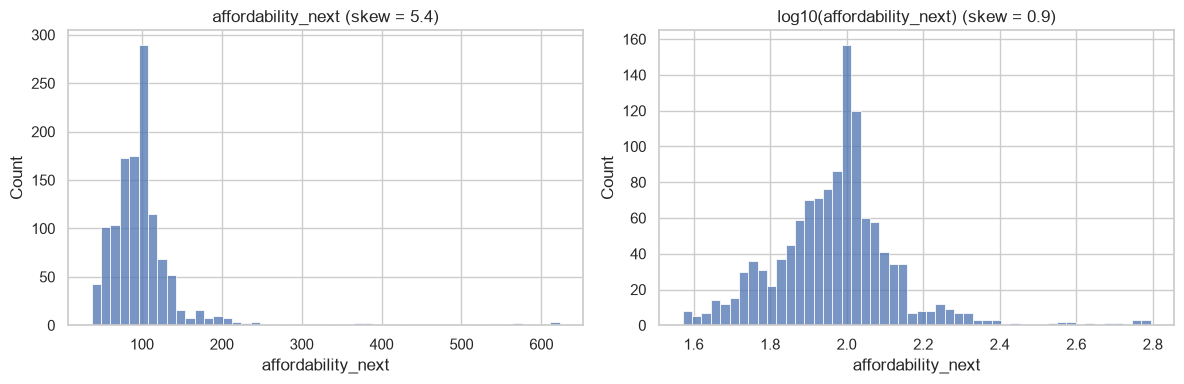

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["affordability_next"], bins=50, ax=axes[0])
axes[0].set_title(f"affordability_next (skew = {df['affordability_next'].skew():.1f})")
sns.histplot(np.log10(df["affordability_next"]), bins=50, ax=axes[1])
axes[1].set_title(f"log10(affordability_next) (skew = {np.log10(df['affordability_next']).skew():.1f})")
plt.tight_layout()
plt.show()

### Inputs: remove what must not be used

We drop from the inputs:
- `affordability_next`: the **target** itself (using it as an input would be the ultimate leak).
- `iso`: a country **identifier**, not a measurement (text, and it would let the model memorise countries).
- `data_reliable`, `is_latest_year`: **constant** in the model-ready file (always 1 and 0 after Day 1 filtering), so they carry no information.

The two leaking features from Day 1 (`affordability_vs_own_avg`, `affordability_position`) were already removed from this file. More on leakage in 1.5.

In [3]:
TARGET = "affordability_next"
drop_cols = [TARGET, "iso", "data_reliable", "is_latest_year"]

X = df.drop(columns=drop_cols)
y = np.log10(df[TARGET])

# time-based split: train up to 2014, test from 2015
SPLIT_YEAR = 2015
is_train = df["year"] < SPLIT_YEAR

X_train, X_test = X[is_train], X[~is_train]
y_train, y_test = y[is_train], y[~is_train]

print(f"Features: {X.shape[1]}")
print(f"Train: {len(X_train)} rows ({len(X_train) / len(X):.0%}), years {df.loc[is_train, 'year'].min()}–{df.loc[is_train, 'year'].max()}")
print(f"Test:  {len(X_test)} rows ({len(X_test) / len(X):.0%}), years {df.loc[~is_train, 'year'].min()}–{df.loc[~is_train, 'year'].max()}")

Features: 25
Train: 950 rows (79%), years 1977–2014
Test:  260 rows (21%), years 2015–2024


In [4]:
# sanity checks: no overlap in time, every country in both sets
assert df.loc[is_train, "year"].max() < df.loc[~is_train, "year"].min()
assert set(df.loc[is_train, "iso"]) == set(df.loc[~is_train, "iso"])
X.columns.tolist()

['year',
 'decade',
 'affordability',
 'real_house_price_index',
 'real_personal_disposable_income',
 'real_hpi_change_pct',
 'real_income_change_pct',
 'affordability_lag1',
 'affordability_lag2',
 'affordability_3yr_avg',
 'nominal_zero',
 'hyperinflation_country',
 'price_shock_up',
 'price_shock_down',
 'gfc_period',
 'region_Africa',
 'region_Asia',
 'region_Central/Eastern Europe',
 'region_Latin America',
 'region_Middle East',
 'region_Nordic',
 'region_North America',
 'region_Oceania',
 'region_Southern Europe',
 'region_Western Europe']